<a href="https://colab.research.google.com/github/Rouliiane/2026_Intro_Python/blob/main/FEEDBACK_Bessard_Julien.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#**Reflexive Exercise**

The goal of this exercise is to develop practical skills in data analysis using Python, using here the library GeoPandas, particularly in visualising spatial data and performing spatial operations.


##**The Hurricane**

The Hurricane Florence exercise consists of plotting the hurricane's trajectory on a map of the United States and identifying which states it passed through by intersecting the trajectory points with state boundaries.

##**The Challenge(s)**

I found the first steps of the exercise relatively easy, as they mainly involved importing, loading and exploring the geospatial data. However, I had more difficulties with the steps 4, 6 and 8, particularly when plotting the data and analysing the hurricane's trajectory. I had to try several approaches and correct my code multiple times before obtaining the expected results. This helped me to better understand how GeoPandas handles spatial data and intersections.


#**The Exercise : Hurricane track analysis**




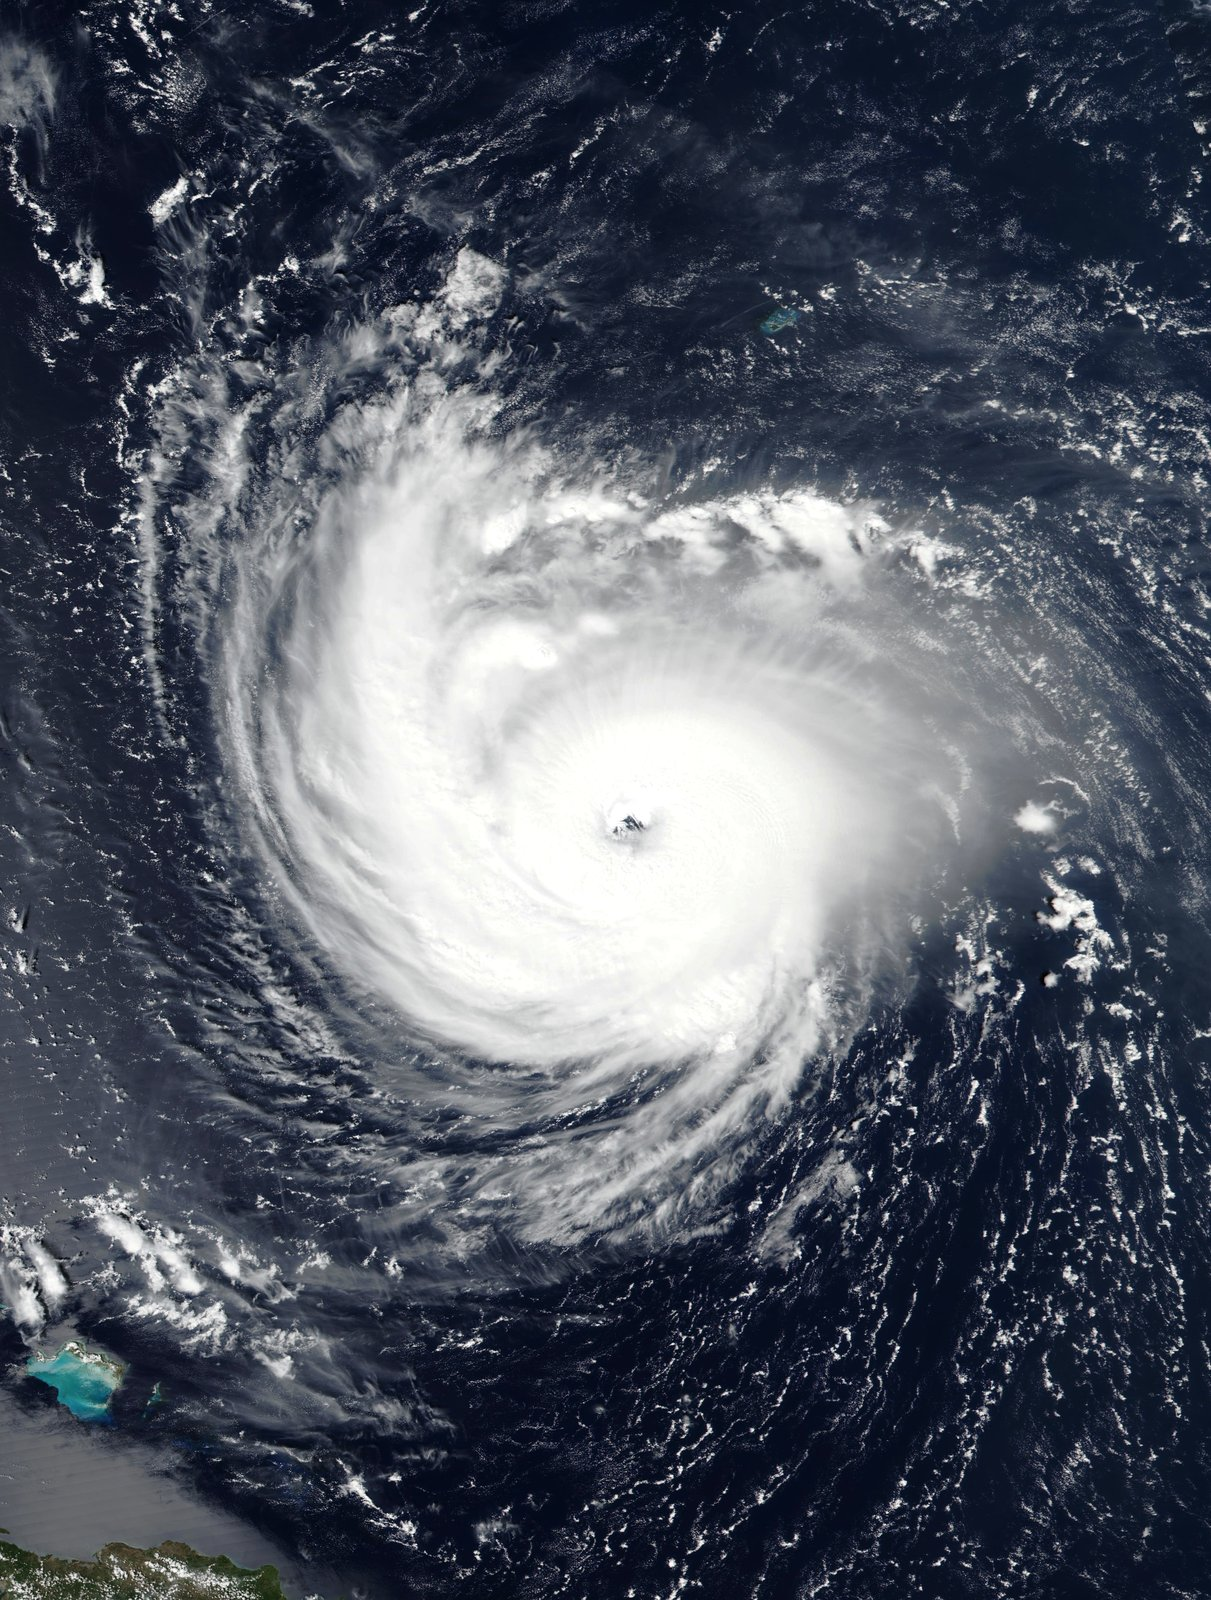
A satellite view of Hurricane Florence over the Atlantic, a clear eye at the centre of a broad spiral of cloud
Hurricane Florence on 11 September 2018, three days before landfall in North Carolina. Image from NASA Worldview via Wikimedia Commons, public domain.

Can you quickly find out which US states Hurricane Florence passed through using geopandas?

Apply geopandas to read in the geospatial data, plot, and analyse the track of Hurricane Florence from 30 August to 18 September 2018. The track is the archived advisory record from the National Hurricane Center; the state boundaries are a US Census Bureau cartographic boundary file.

References:

Introduction to GeoPandas — geopandas' official website
Geopandas: an introduction — Automating GIS Processes
Use Data for Earth and Environmental Science in Open Source Python
The Shapely User Manual
Geospatial Analysis with Python and R

##**Importing the datas**

In [ ]:
# Pre-supplied: download and cache the two real data files.
import pooch

states_path = pooch.retrieve(
    url="https://raw.githubusercontent.com/gse-unil/2026_MLEES_book/main/data/part-I/gz_2010_us_040_00_5m.json",
    known_hash="sha256:7a8c022e063a34a83f35984cde6c81992ece5983f8cc4459ed02e40687739573",
    fname="us_states.geojson",
    path=pooch.os_cache("mlees"),
)
track_path = pooch.retrieve(
    url="https://raw.githubusercontent.com/gse-unil/2026_MLEES_book/main/data/part-I/florence.csv",
    known_hash="sha256:385691583ee41682a1c905e042c56ea362609fb04645934bdda7911c55c8b63f",
    fname="florence.csv",
    path=pooch.os_cache("mlees"),
)

ℹ️ Where the tools come from

Every tool the questions need has been demonstrated already. read_file, .plot(), GeoDataFrame, gpd.points_from_xy, .crs, geom_type, the MultiPolygon type, .isin(), overlay, .centroid, to_crs, buffer and the spatial predicates are from this subchapter's lecture; .head() and boolean filtering are from 1.5, and unique from 1.5's earthquake exercise. ax.annotate, which Q8 uses to label each state, is from 1.4.

##**The easy steps**

All the following steps have been made without any trouble.

**Q1) Import geopandas and pandas**

Import geopandas as gpd, pandas as pd, and matplotlib's pyplot as plt.

In [ ]:
import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt

**Q2) Read the state boundary file with geopandas' read_file function**

The file is cached at states_path. Call the result country.

In [ ]:
country = gpd.read_file(states_path)

**Q3) Have a look at the data. What type of geometries does it contain?**

Print the first few rows, and answer the geometry question in a comment.

In [ ]:
# Print out the first few lines of the data
country.head(5)

,GEO_ID,STATE,NAME,LSAD,CENSUSAREA,geometry
0,0400000US01,01,Alabama,,50645.326,"MULTIPOLYGON (((-88.12466 30.28364, -88.08681 ..."
1,0400000US02,02,Alaska,,570640.950,"MULTIPOLYGON (((-166.10574 53.98861, -166.0752..."
2,0400000US04,04,Arizona,,113594.084,"POLYGON ((-112.53859 37.00067, -112.53454 37.0..."
3,0400000US05,05,Arkansas,,52035.477,"POLYGON ((-94.04296 33.01922, -94.04304 33.079..."
4,0400000US06,06,California,,155779.220,"MULTIPOLYGON (((-122.42144 37.86997, -122.4213..."


**Q5) Create a GeoDataFrame from the florence DataFrame**

Build the geometry column from the Long and Lat columns with gpd.points_from_xy, and call the result gdf_florence. Then look at its first few rows.

In [ ]:
# Create a geodataframe from the hurricane florence dataframe
gdf_florence = gpd.GeoDataFrame(florence, geometry = gpd.points_from_xy(florence["Long"], florence["Lat"]), crs="EPSG:4326")


**Q7) What is the coordinate reference system of the data?**

Check it for both layers, and say in a comment whether they match — two layers only line up on one pair of axes if they share a crs.

In [ ]:
print(country.crs)
print(gdf_florence.crs)

EPSG:4326
EPSG:4326


##**The challenging steps**
**The steps 4, 6 and 8 were more challenging** because they required combining several concepts and understanding how GeoPandas handles spatial data, rather than simply applying individual commands.
###**Step 4**

**Q4) Have a look at the data on a map using geopandas' .plot() method.**

*Exclude Alaska and Hawaii using the NAME attribute and pandas' .isin() method. Specify the figsize to be 30 x 20.*

####**The first code**

In step 4, my  mistake was putting the boolean mask directly to the **.plot()** method instead of using it to filter the GeoDataFrame first. In my initial code,

I knew I had to exclude the Alaska and Hawaii states by using a Boolean mask. Howewer, I set it **inside the plot() function.** This argument is then interpreted as the name or values of the column to be plotted, rather than as a filter to select the states.

As a result, the code did not correctly select the states to display and could produce an error.



<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

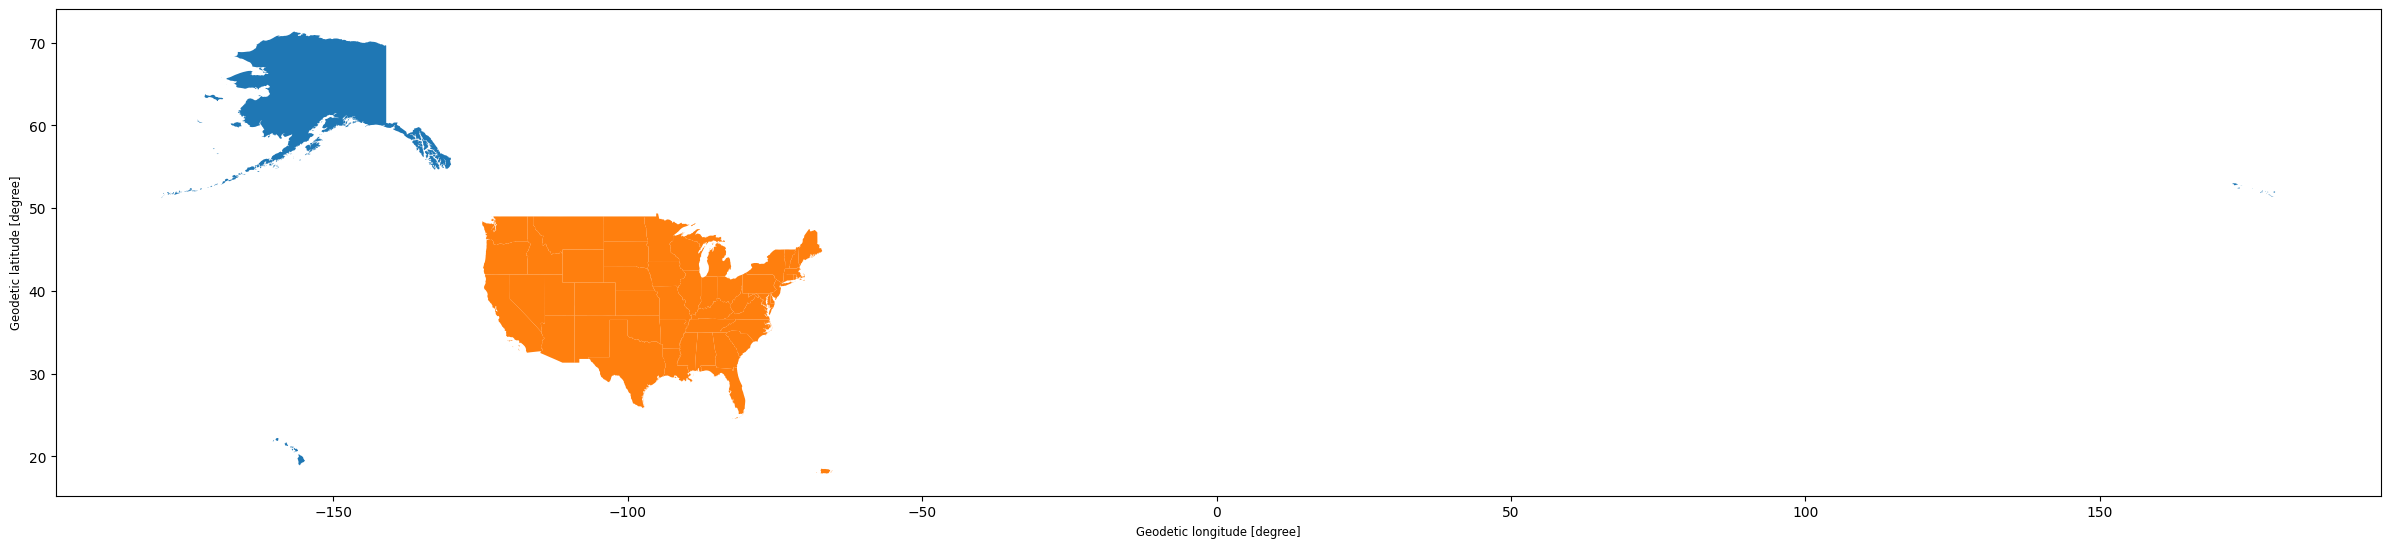

In [ ]:
country.plot(~country["NAME"].isin(["Alaska","Hawaii"]), figsize=(30, 20))

I solved this by applying the mask to country before calling **.plot()**, which allowed me to exclude Alaska and Hawaii and display the remaining states correctly.

####**Corrected code**

<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

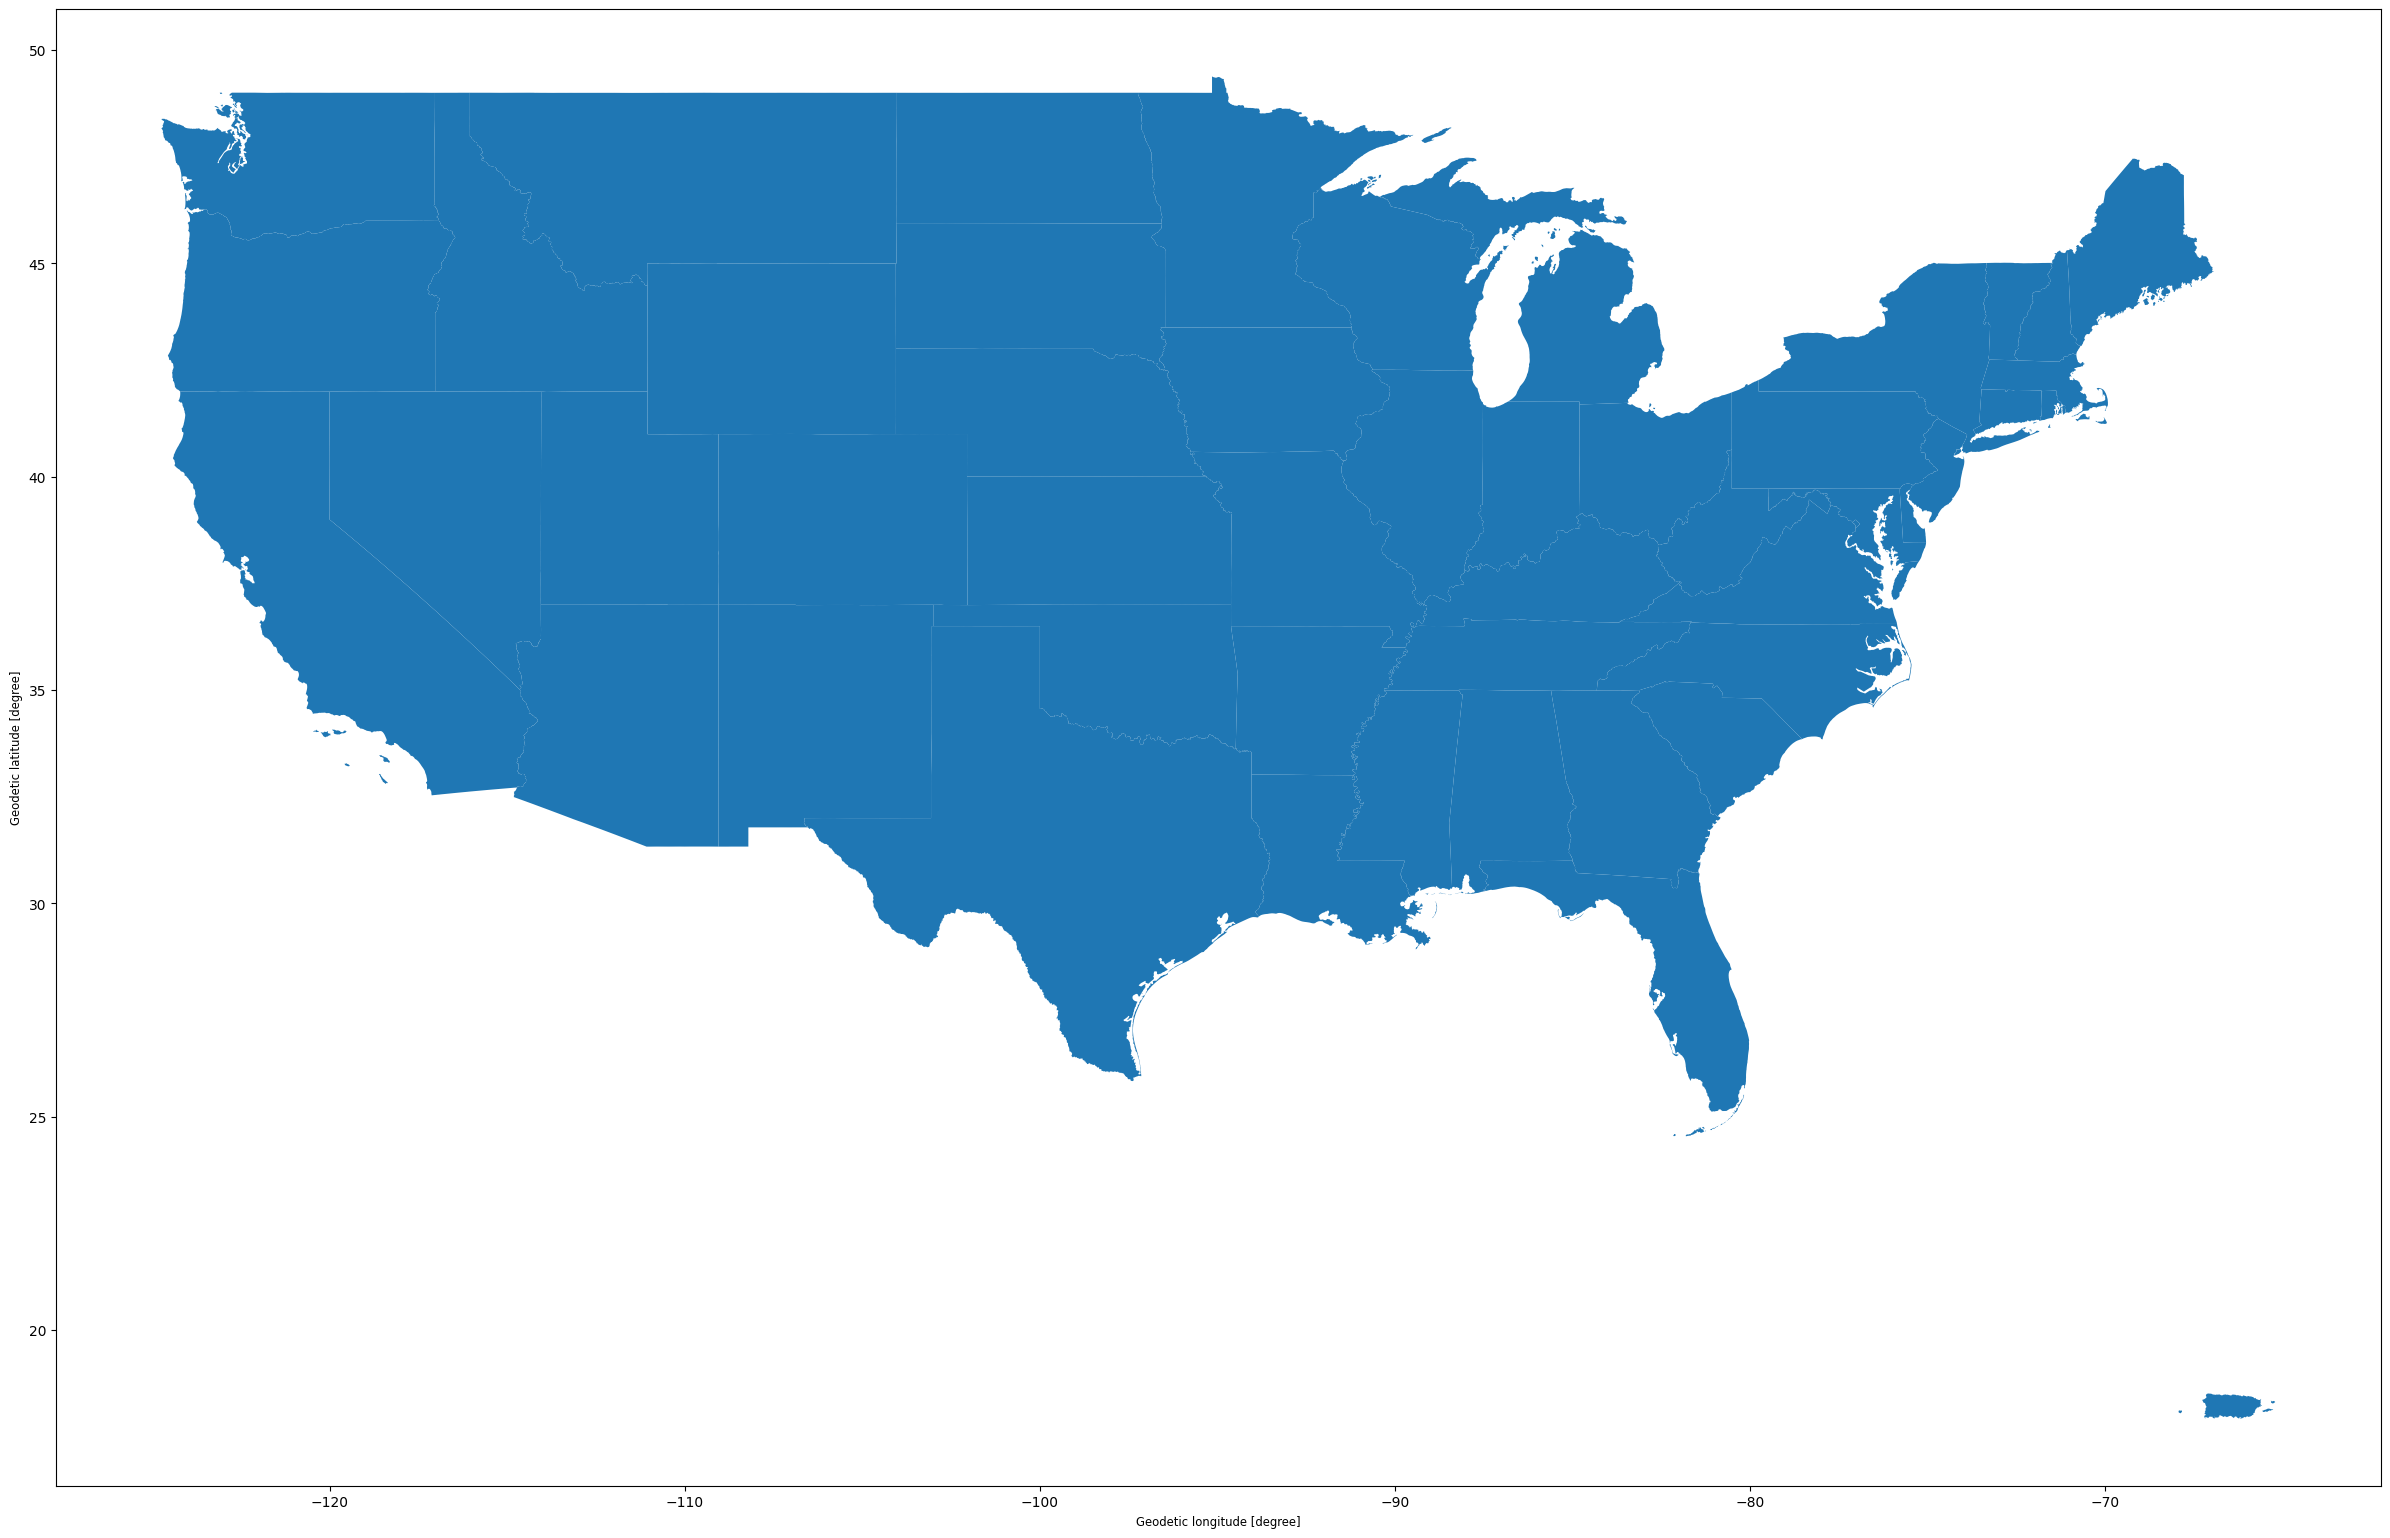

In [ ]:
country[(~country["NAME"].isin(["Alaska","Hawaii"]))].plot(figsize=(30, 20))

After having checked the topics 1.5.6 Plotting in 1.5) Tabular Data with pandas, I applied the Boolean mask directly to country **before calling plot()**. This filtered out Alaska and Hawaii and successfully displayed the remaining US states on the map.

###**Step 6**

 **Q6) Plot the US states map (without Alaska and Hawaii) and hurricane Florence together.**

 *Draw the states as a base map, then plot the hurricane positions on top in a colour that stands out.*

####**The first code**

In step 6, my mistake was plotting the hurricane positions separately from the US states map without specifying that both layers should be displayed on the same axes.

In my initial code, I used **.plot()** for the states and then called gdf_florence.plot() independently. As a result, the hurricane positions appeared on a separate plot instead of overlaying the US map.  

<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

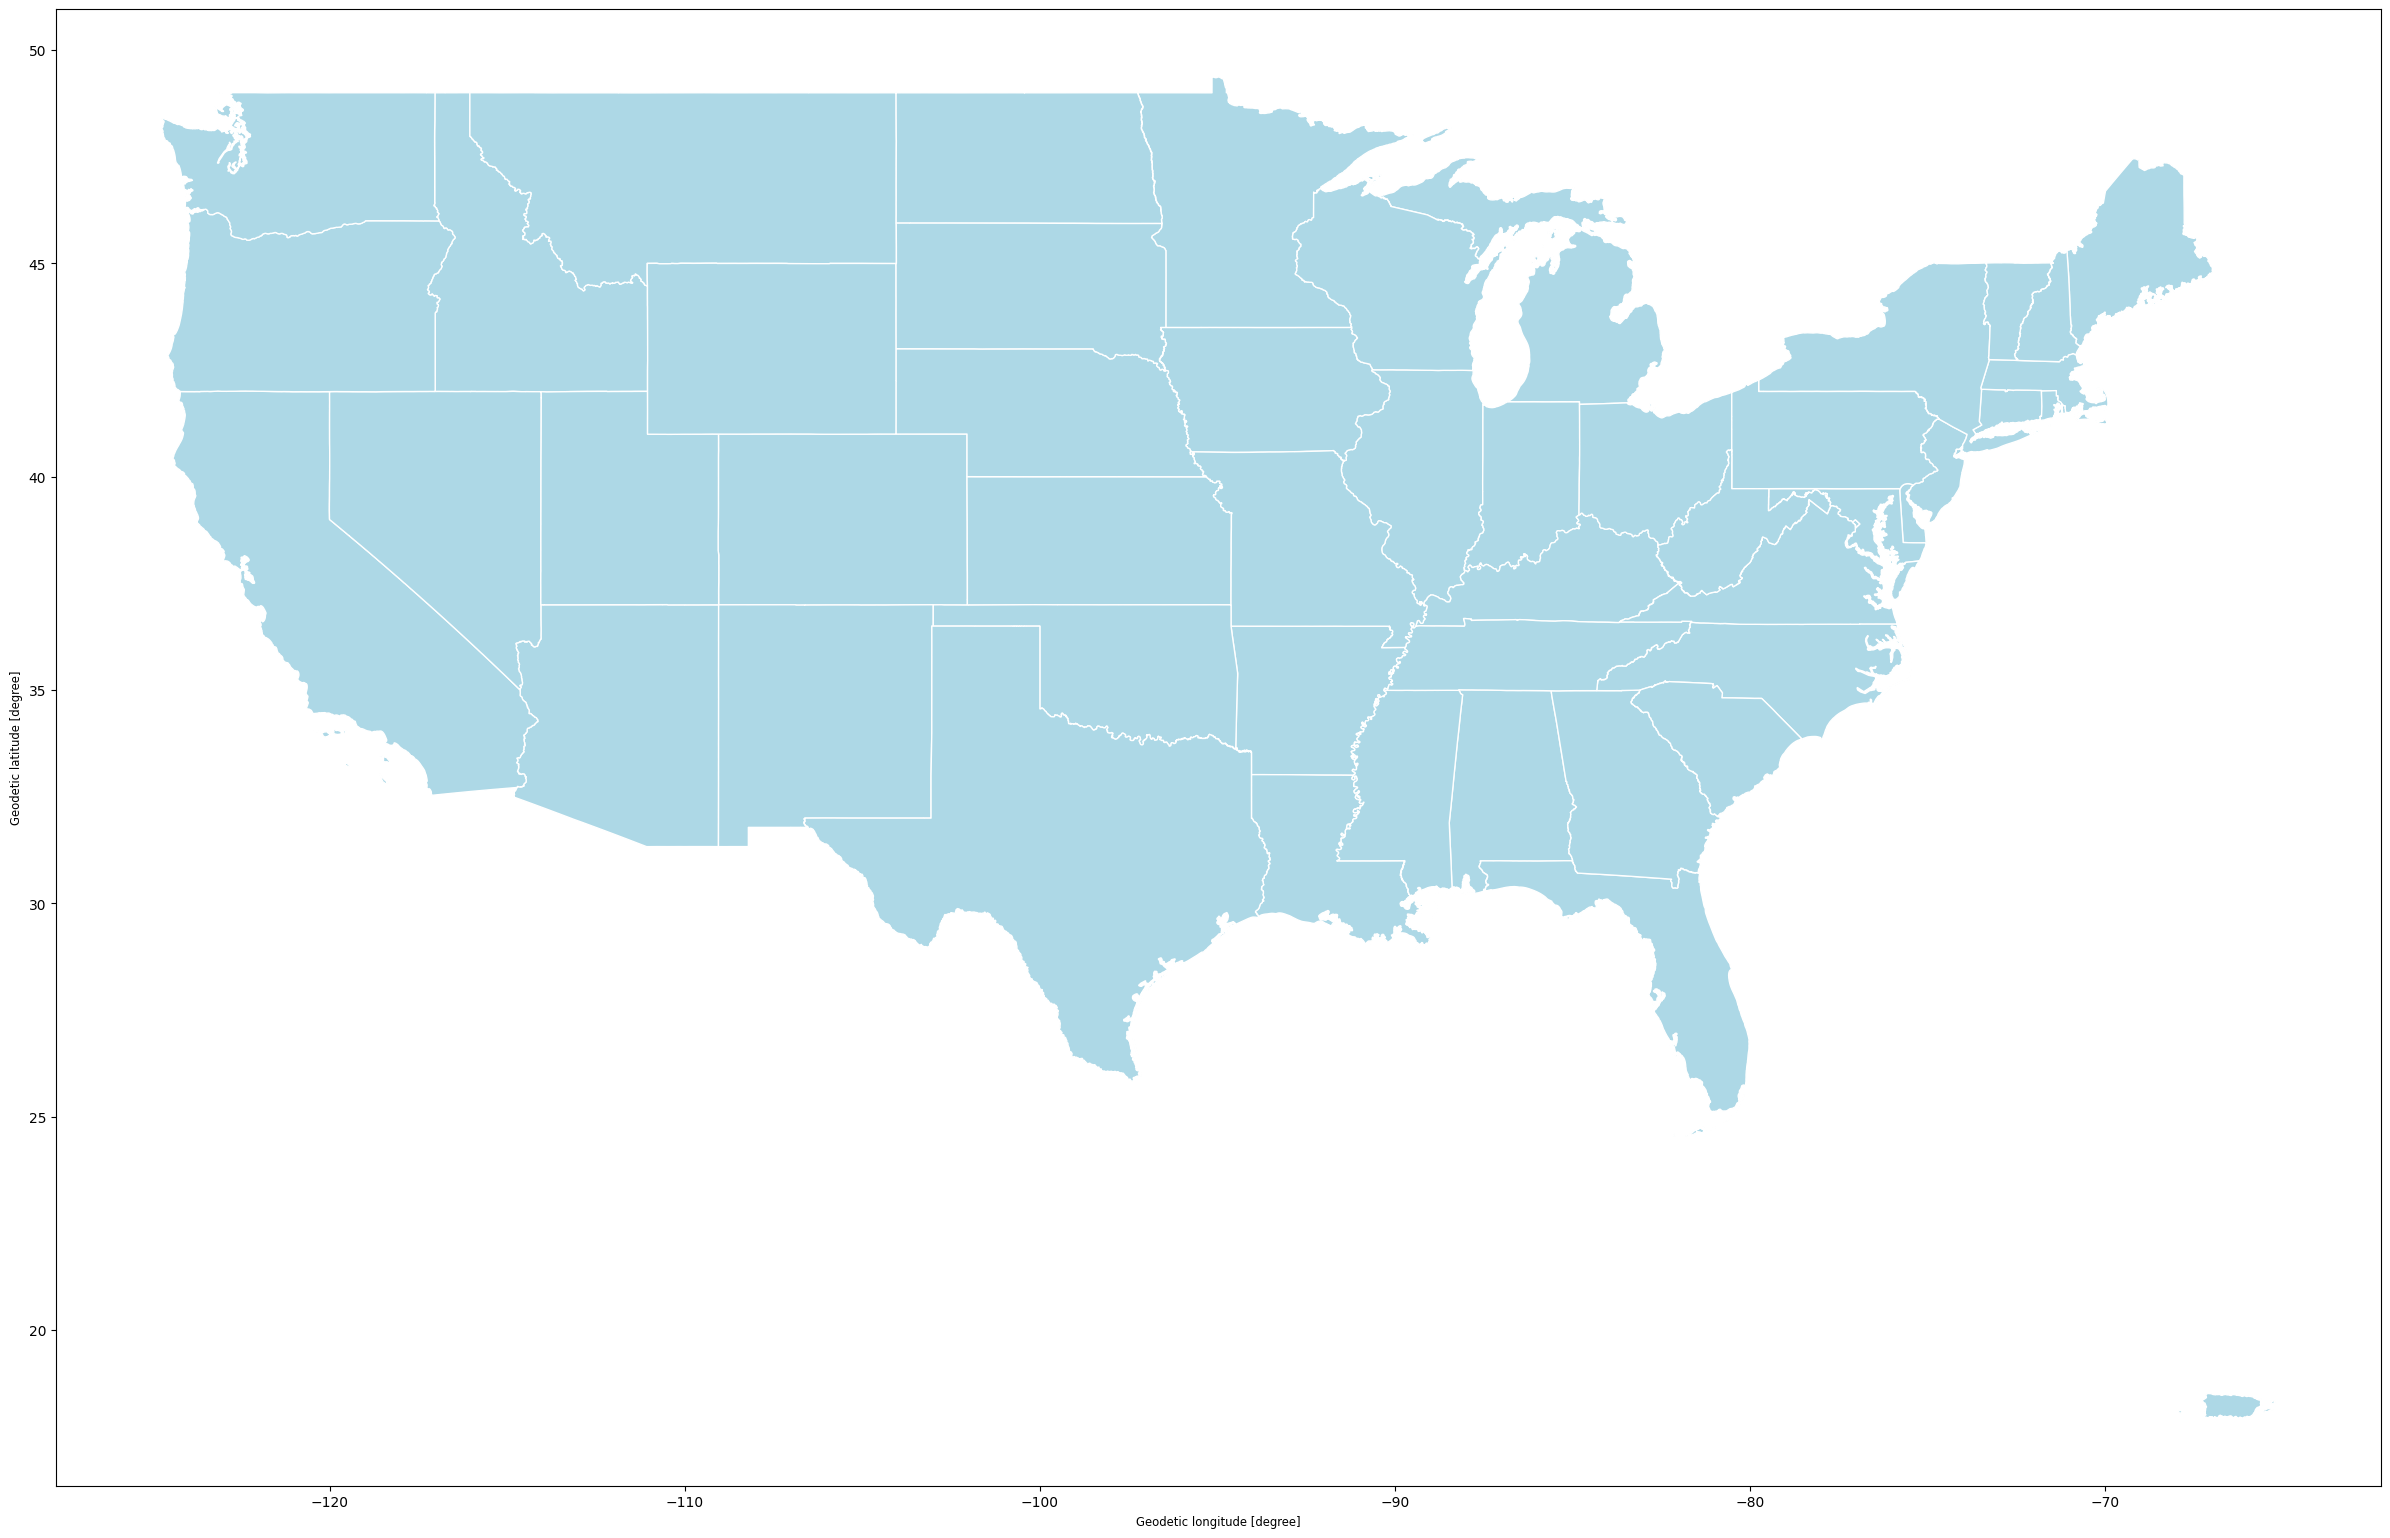

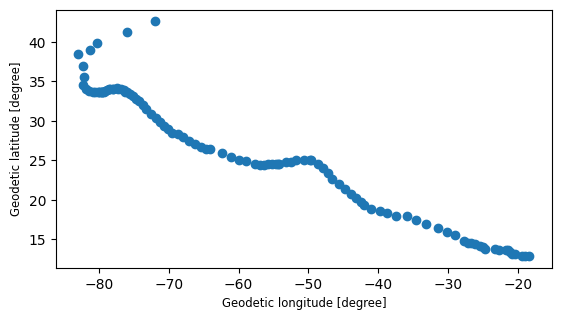

In [ ]:
country[(~country["NAME"].isin(["Alaska","Hawaii"]))].plot(figsize=(30, 20), facecolor="lightblue", edgecolor="white")
gdf_florence.plot()

To correct this, I need to create a figure and axes using plt.subplots() and set the same ax argument to both .plot() methods.

####**Corrected code**

<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

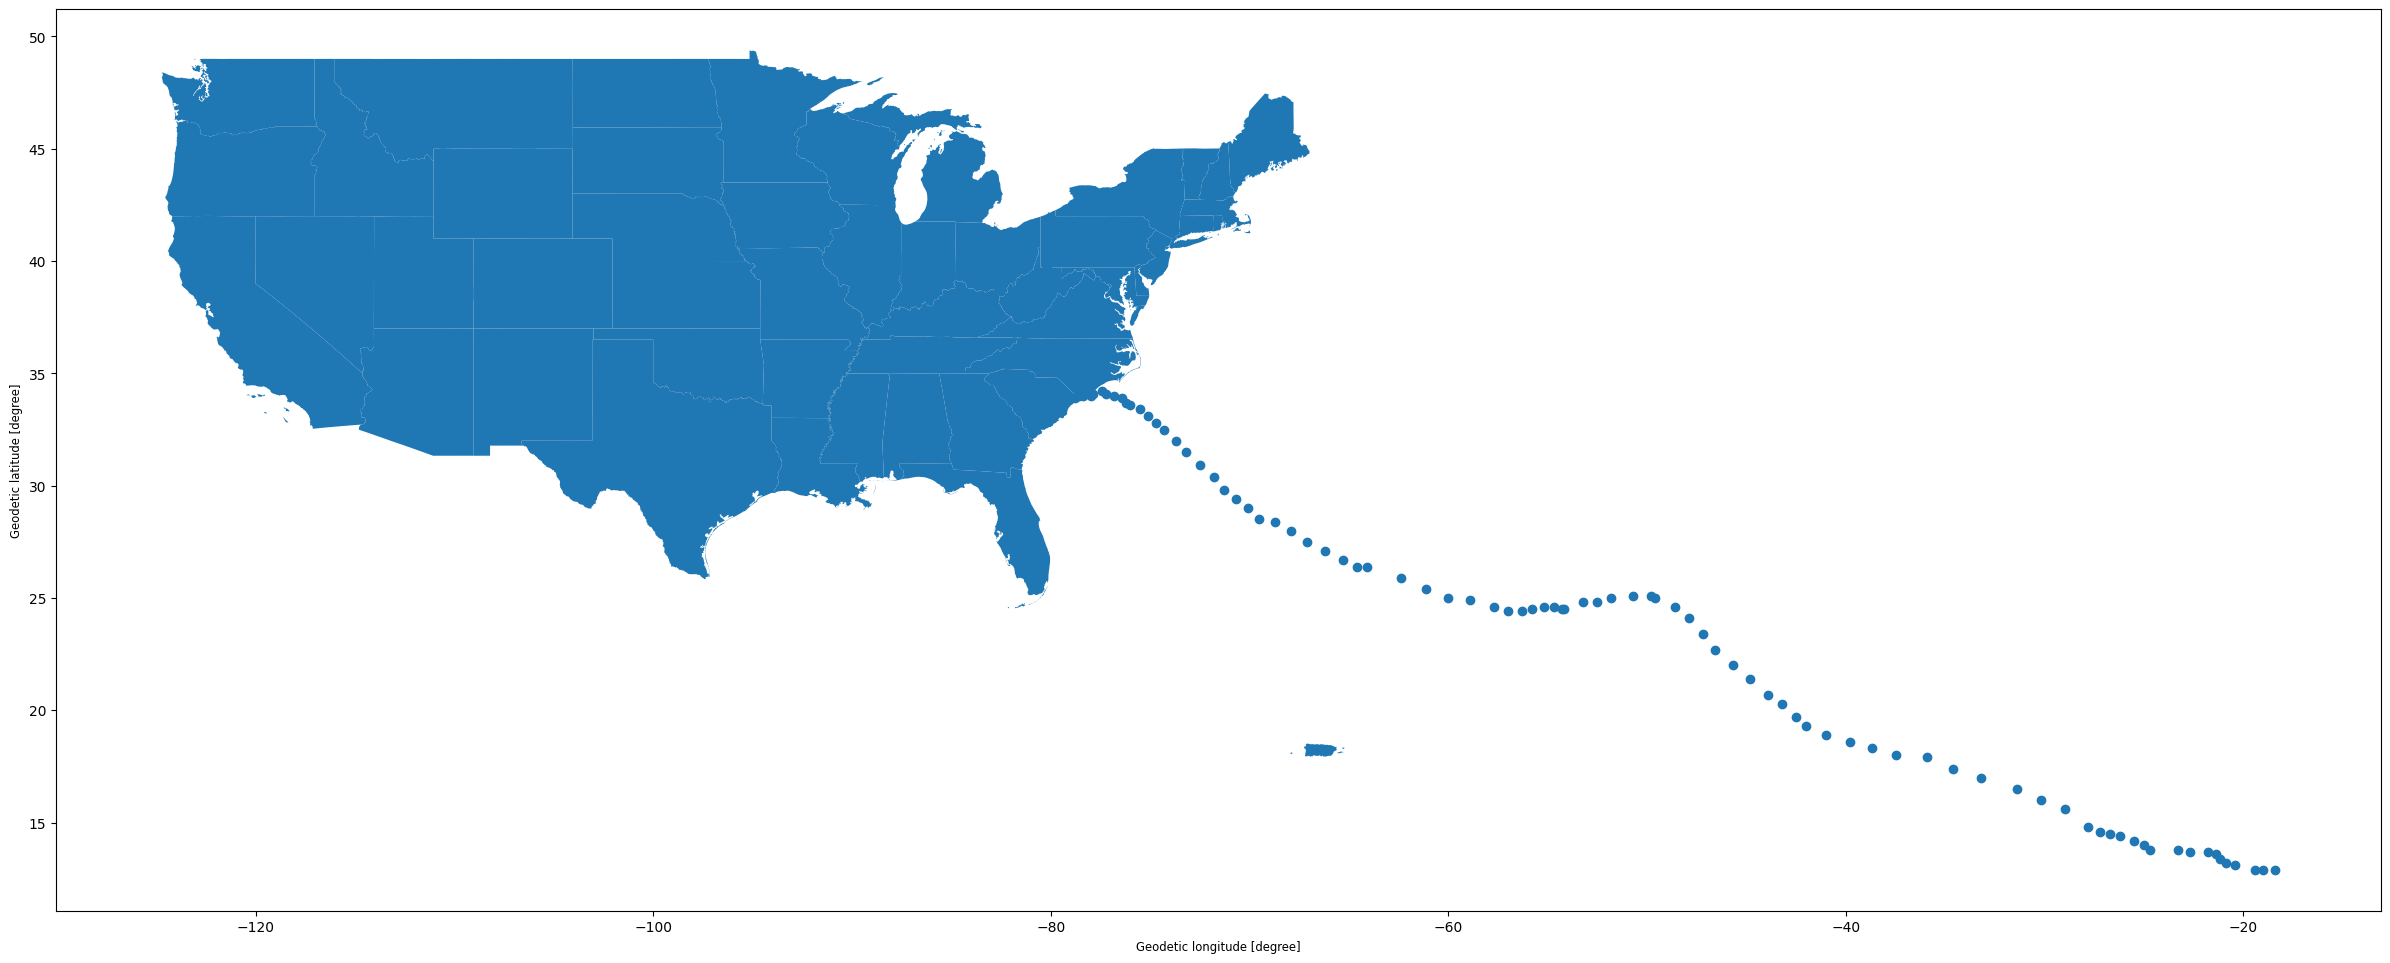

In [ ]:
fig, ax = plt.subplots(figsize=(30,20))

country[(~country["NAME"].isin(["Alaska","Hawaii"]))].plot(ax=ax,figsize=(30, 20))
gdf_florence.plot(ax=ax)

By putting the same ax argument to both .plot() methods. After looking at the chapter 1.6.5, I then created a figure and axes using **fig, ax = plt.subplots()** and used **ax=ax** in both .plot() methods to display both layers on the same map. The hurricane positions are now displayed on the top of the US states map instead of in a separate plot. This allows me to visualise Hurricane Florence's trajectory in relation to the states it crossed.

###**The second code**
The obtained results are confunded in the plots, because they have the same default color. Using the tools **facecolor** and **edgecolor**, I then improved the map by setting the states colour to light blue and their borders to white, then plotting Hurricane Florence's positions in red.

####**Enhanced code**

<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

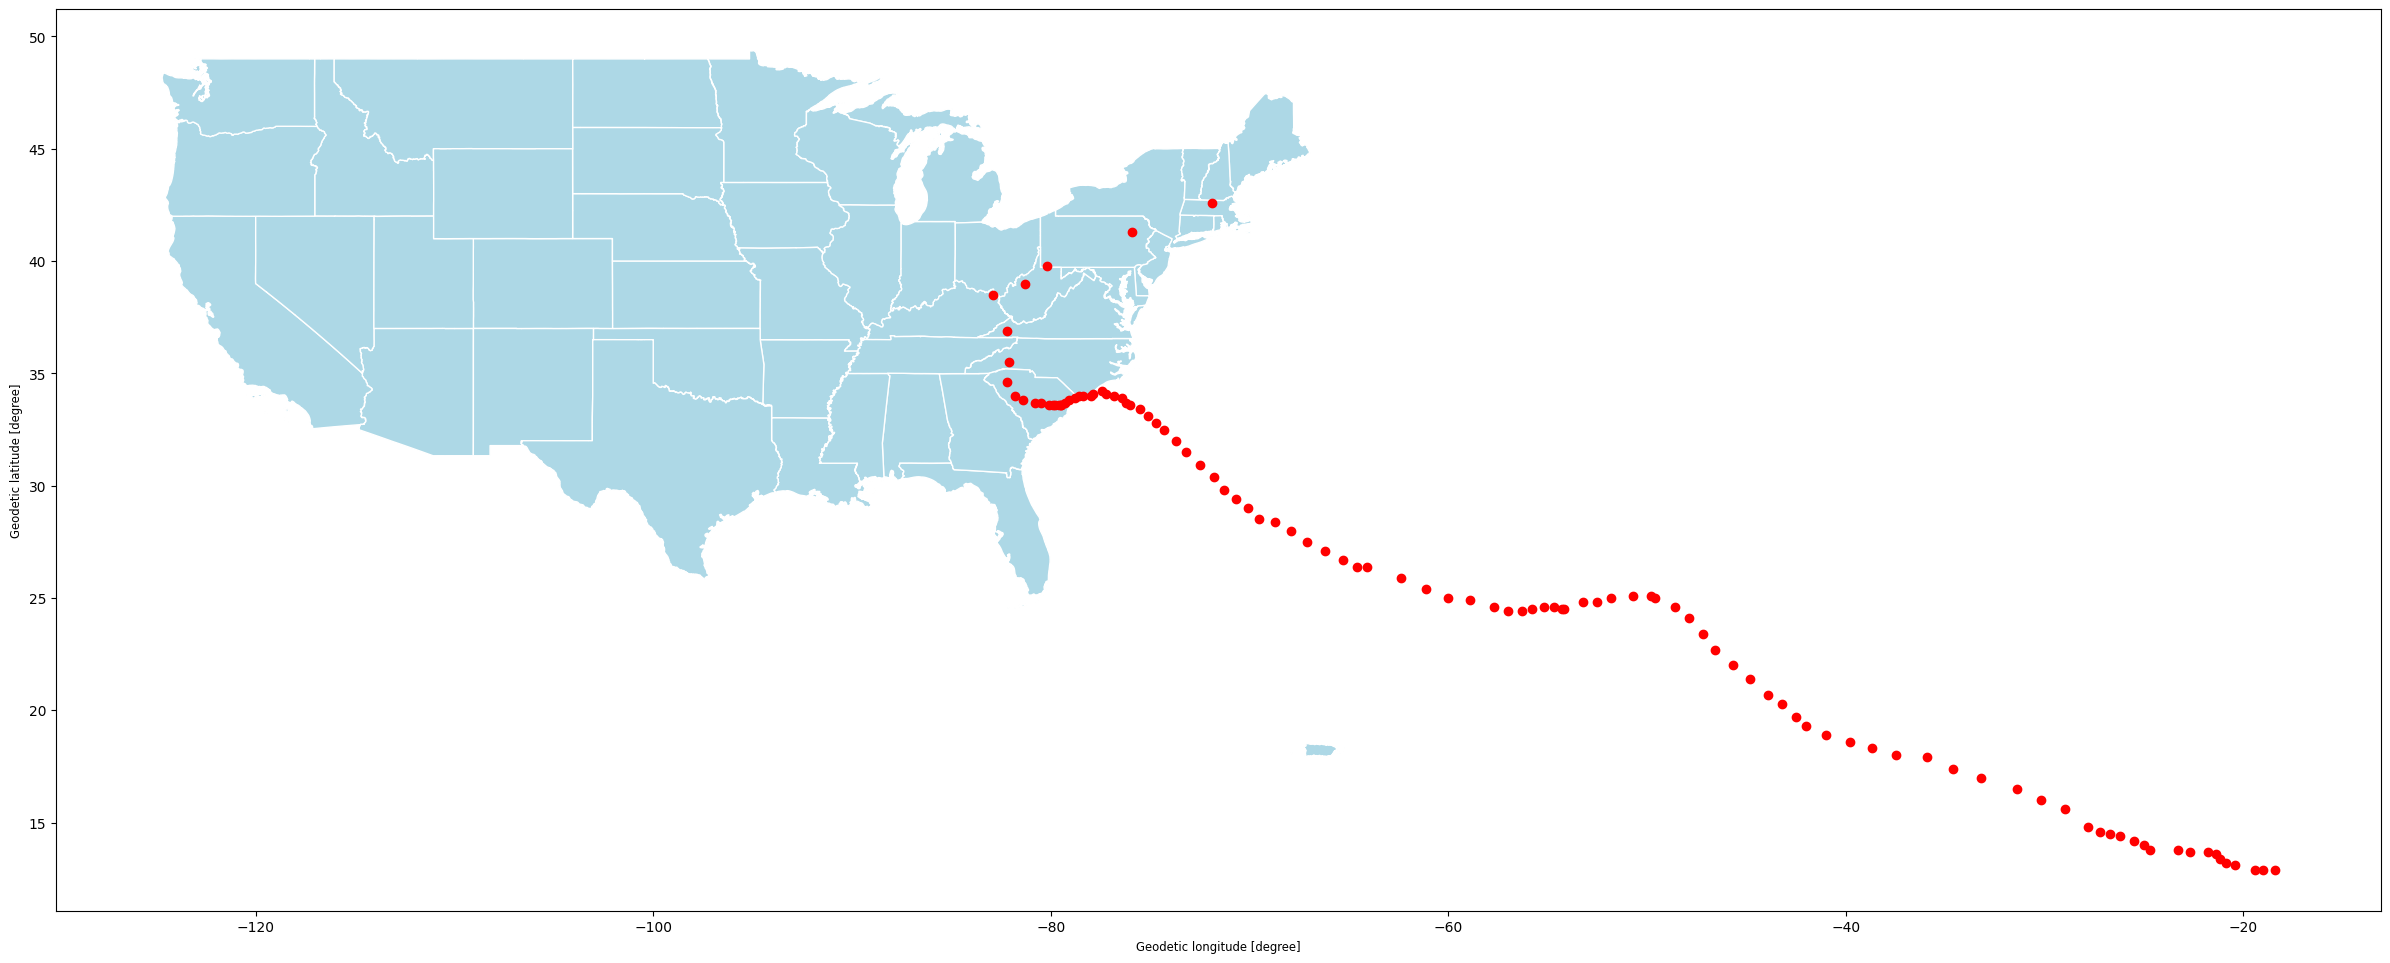

In [ ]:
fig, ax = plt.subplots(figsize=(30,20))
country[(~country["NAME"].isin(["Alaska","Hawaii"]))].plot(ax=ax,figsize=(30, 20), facecolor="lightblue", edgecolor="white")
gdf_florence.plot(ax=ax, facecolor="red")

This created a clear contrast and make the hurricane track easier to distinguish.

###**Step 8**

 **Q8) Which states did the hurricane pass through?**

**ℹ️ Hint**

*One approach is to plot the trajectory over the US map, annotate each state with its name, and read the answer off the figure. Other approaches are more than welcome — overlay with how="intersection" will give you the track points that fall inside a state polygon, and the NAME column of the result then answers the question directly.*



####**The first code**
In my initial code, I used **gpd.overlay()** to find the intersections between the US states and Hurricane Florence's positions as explained in the 1.6.6 topic. As a result, the output could be empty, so calling .plot() displayed only the axes without the map or the hurricane positions.

/usr/local/lib/python3.13/dist-packages/geopandas/tools/overlay.py:386: UserWarning: `keep_geom_type=True` in overlay resulted in 25 dropped geometries of different geometry types than df1 has. Set `keep_geom_type=False` to retain all geometries
  result = _collection_extract(result, geom_type, keep_geom_type_warning)
/usr/local/lib/python3.13/dist-packages/geopandas/plotting.py:1408: UserWarning: The GeoSeries you are attempting to plot is empty. Nothing has been displayed.
  return plot_dataframe(data, *args, **kwargs)


<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

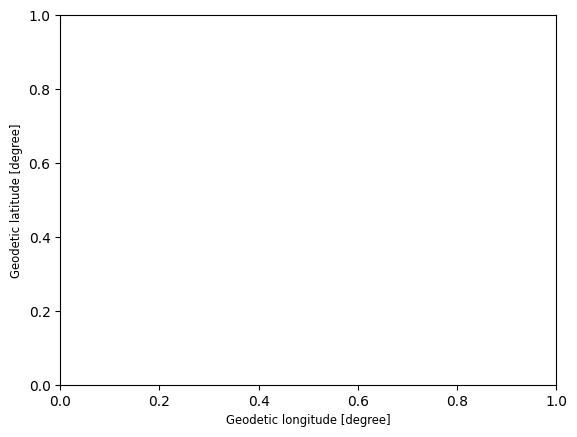

In [ ]:
countries_overlay = gpd.overlay(
    country,
    gdf_florence,
    how="intersection"
)

countries_overlay.plot()


The code worked, but didn't plotted anything excepted the axes.

####**The second code**
It first appeared that my **figure had no background at all**, so the overlay() method cannot plot anything. I then improved my initial code by creating a figure and axes, then plotting the US states as a background layer.

I then **stacked the modified GeoDataFrame of country** into a variable (country_sorted) to use it directly into the .overlay() method.

Finally, by using **ax=ax in both .plot() methods**, I ensured that the intersection results were displayed on top of the map instead of plotting them separately.

<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

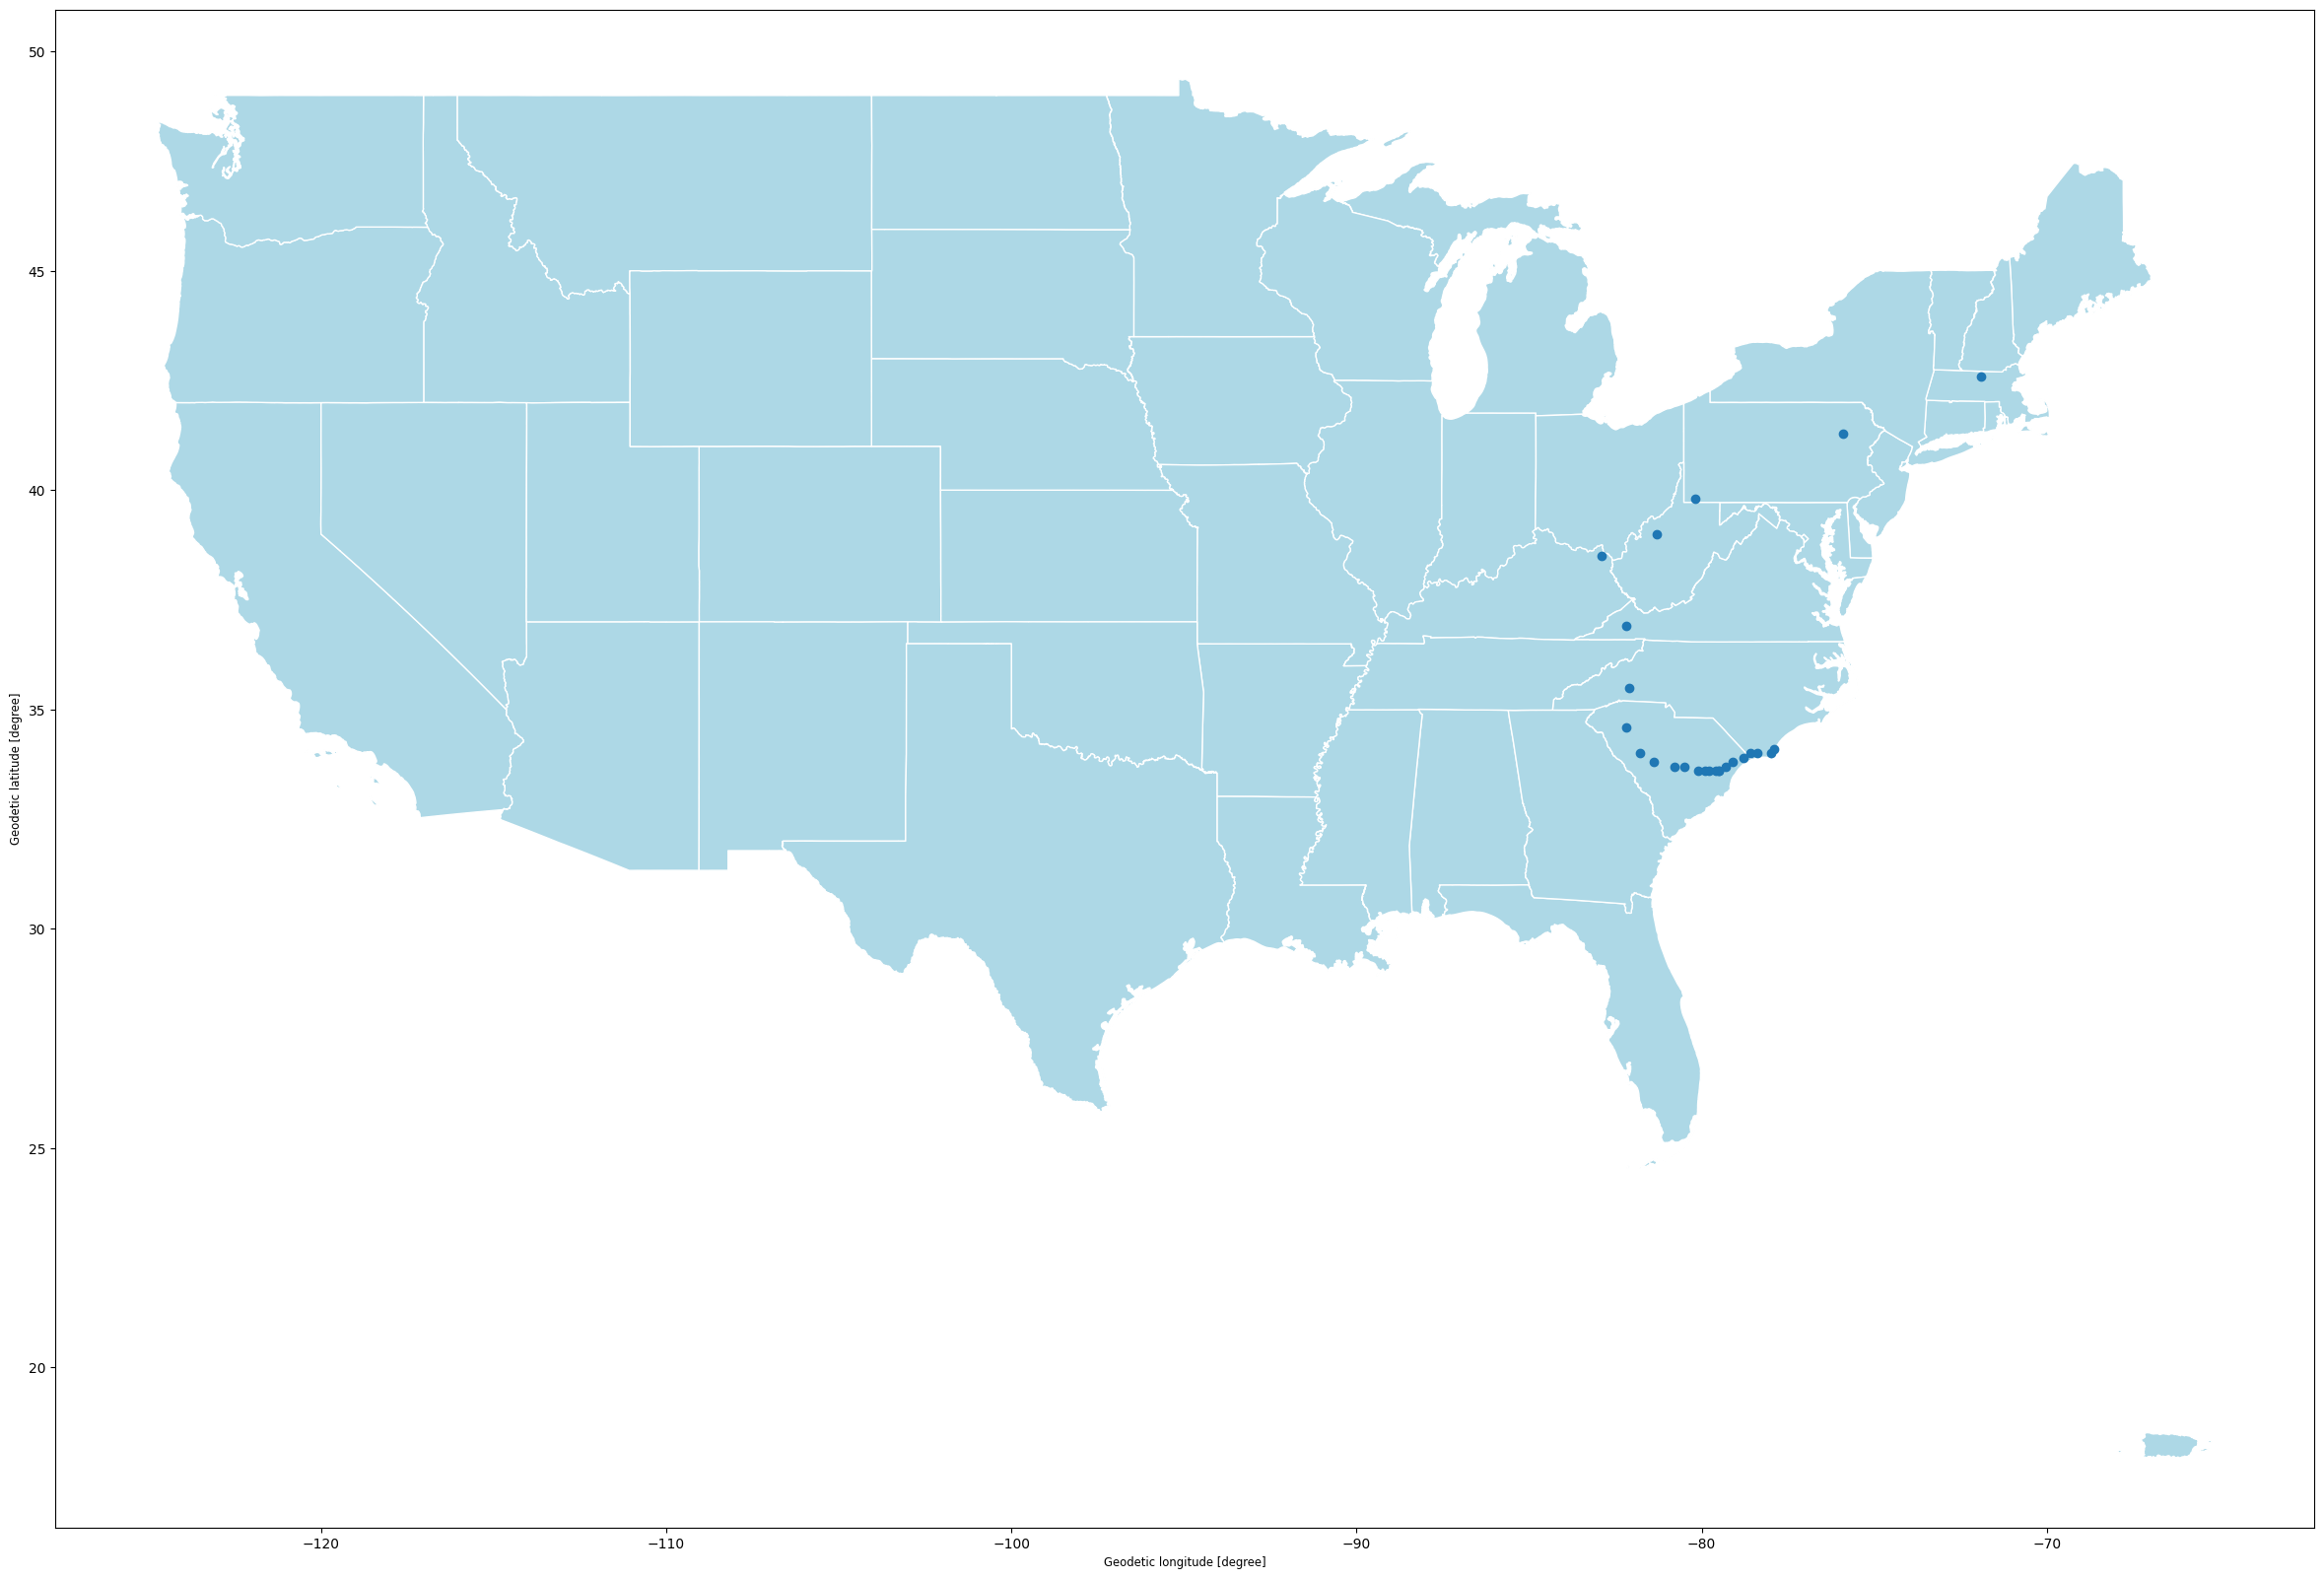

In [ ]:
fig, ax = plt.subplots(figsize=(30,20))

country_sorted = country[~country["NAME"].isin(["Alaska", "Hawaii"])]
country_sorted.plot(ax=ax, facecolor="lightblue", edgecolor="white")

countries_overlay = gpd.overlay(
    gdf_florence,
    country_sorted,
    how="intersection")

countries_overlay.plot(ax=ax)


####**The third code**

For the last part, which was to annotate the states hit by the hurricane, I managed to print the states hit by the hurricane, using the method **.unique()**. But even after consulting the topics I did not find all the relevant documentation to annotate them on the map.

In [ ]:
states_hit = countries_overlay["NAME"].unique()
print(states_hit)

['North Carolina' 'South Carolina' 'Virginia' 'Kentucky' 'West Virginia'
 'Pennsylvania' 'Massachusetts']


#### Trying to use CHatGPT wisely

That is why I asked ChatGPT which complementary method I could use. He told me to use the method **.iterrow()**,and geometry property **.geometry.centroid** in a loop with its condition. To annotate I used the documentation on topic 1.4.5.

I first tried to have a look each line of country_sorted, but an error appeared.

In [ ]:
for state in country_sorted.iterrows():
    print(state["NAME"])

TypeError: tuple indices must be integers or slices, not str

*TypeError: tuple indices must be integers or slices, not str.*

It didn't work, because .iterrows() returns a tuple containing the row **index** and the row data. Therefore, state contains the entire tuple, not just the row. To solve it, I have to add the index into the loop.

In [ ]:
for idx, state in country_sorted.iterrows():
    print(state["NAME"])

Alabama
Arizona
Arkansas
California
Colorado
Connecticut
Delaware
District of Columbia
Florida
Georgia
Idaho
Illinois
Indiana
Iowa
Kansas
Kentucky
Louisiana
Maine
Maryland
Massachusetts
Michigan
Minnesota
Mississippi
Missouri
Montana
Nebraska
Nevada
New Hampshire
New Jersey
New Mexico
New York
North Carolina
North Dakota
Ohio
Oklahoma
Oregon
Pennsylvania
Rhode Island
South Carolina
South Dakota
Tennessee
Texas
Utah
Vermont
Virginia
Washington
West Virginia
Wisconsin
Wyoming
Puerto Rico


I then added the condition, which is here if the name of the state is found in the list of the hit states, we must annotate the state.

In [ ]:
for idx, state in country_sorted.iterrows():
    if state["NAME"] in states_hit:
        print(state["NAME"])


Kentucky
Massachusetts
North Carolina
Pennsylvania
South Carolina
Virginia
West Virginia


For the next step I tried to calculate the centroid of the states with the geometry property **.geometry.centroid()**. This allows to determine the center of the state where the annotation will going to be displayed.

In [ ]:
for idx, state in country_sorted.iterrows():
    if state["NAME"] in states_hit:
        center = state.geometry.centroid
print(point)

POINT (-80.61385445867171 38.6425100580366)


Finally, I tried to nnoted the name of the states on the centroids, using the documentation found in topic 1.4.5.

In [ ]:
for idx, state in country_sorted.iterrows():
    if state["NAME"] in states_hit:
        center = state.geometry.centroid
        ax.annotate(state["NAME"], xy=center)

TypeError: cannot unpack non-iterable Point object

*TypeError: cannot unpack non-iterable Point object*

The code retruned an error because center is an geometrical object and ax.annotate excepts a tuple with coordinates (x,y). ChatGPT told me to use the form **variable.x** and **variable.y**.





In [ ]:
for idx, state in country_sorted.iterrows():
    if state["NAME"] in states_hit:
        center = state.geometry.centroid
        ax.annotate(state["NAME"], xy=(center.x, center.y))

Finally, the code put all together reveals the names of the states hit by the hurricane only.

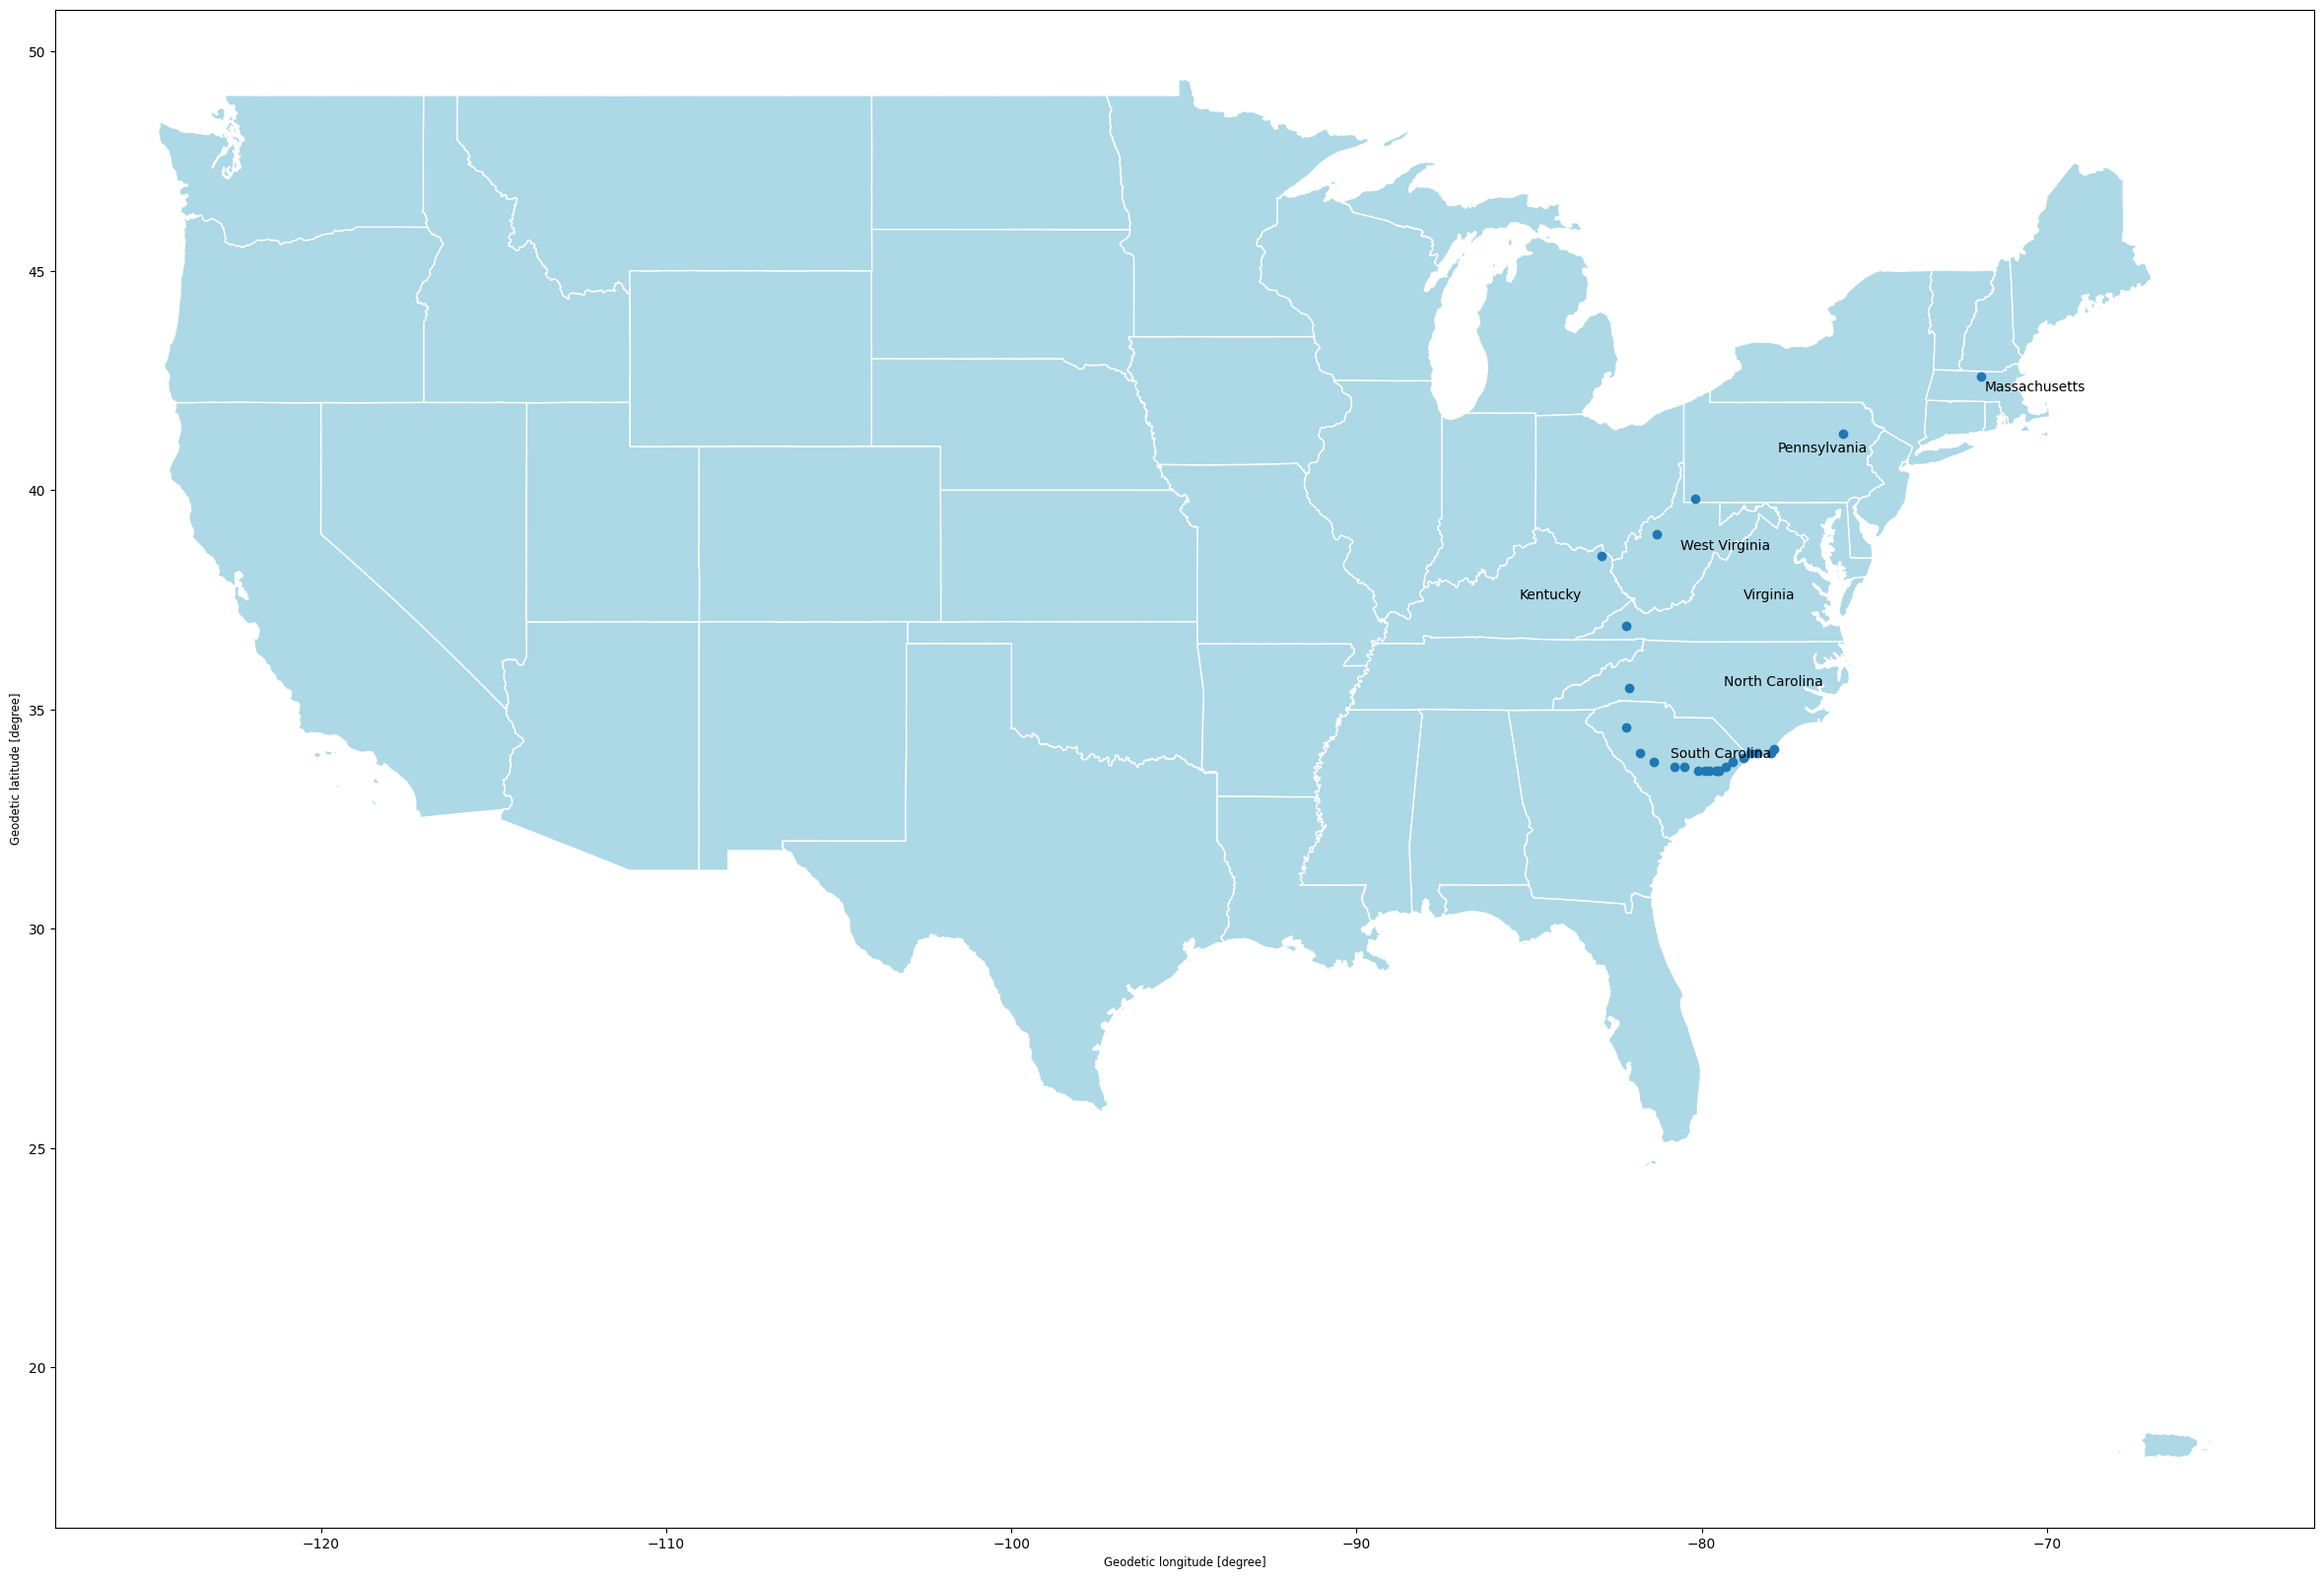

In [ ]:
fig, ax = plt.subplots(figsize=(30,20))

country_sorted = country[~country["NAME"].isin(["Alaska", "Hawaii"])]
country_sorted.plot(ax=ax, facecolor="lightblue", edgecolor="white")

countries_overlay = gpd.overlay(
    gdf_florence,
    country_sorted,
    how="intersection")

countries_overlay.plot(ax=ax)

for idx, state in country_sorted.iterrows():
    if state["NAME"] in states_hit:
        center = state.geometry.centroid
        ax.annotate(state["NAME"], xy=(center.x, center.y))

#Conclusion

This exercise helped me improve my understanding of GeoPandas and spatial data analysis. I learned how to display a trajectory on a map  and identify the regions crossed using a spatial intersection. The most challenging steps required me to troubleshoot errors, understand how geometry types affect the results of gpd.overlay(), and combine several methods to label the relevant states. Overall, this exercise taught me the importance of testing different approaches and understanding each step of the code rather than simply applying commands.